## Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/Dataset.csv')

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (26305, 6)


,timestamp,cpu_utilization,memory_usage,storage_usage,workload,Resource Allocation
0,2022-01-01 00:00:00,39.963210,37.120463,77.268825,87.597635,51.911114
1,2022-01-01 01:00:00,86.060728,51.540619,56.655229,100.000000,61.732726
2,2022-01-01 02:00:00,68.566681,NaN,62.418368,100.000000,75.685323
3,2022-01-01 03:00:00,57.903428,51.213742,95.346718,100.000000,67.873120
4,2022-01-01 04:00:00,NaN,74.822334,84.865431,93.433681,65.148501


## Feature selection and missing-value handling

In [2]:
from sklearn.impute import SimpleImputer

# Select features for clustering
features = ["cpu_utilization", "memory_usage", "storage_usage", "workload"]
X = df[features].copy()

# Check missing values
print("Missing values before:")
print(X.isnull().sum())

# Replace missing values with each column's median
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("\nMissing values after:")
print(X_imputed.isnull().sum())

Missing values before:
cpu_utilization    2819
memory_usage       3071
storage_usage      3306
workload              0
dtype: int64

Missing values after:
cpu_utilization    0
memory_usage       0
storage_usage      0
workload           0
dtype: int64


## Feature Scaling

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Scaled data shape:", X_scaled.shape)
print("Feature means:", X_scaled.mean(axis=0).round(2))
print("Feature standard deviations:", X_scaled.std(axis=0).round(2))

Scaled data shape: (26305, 4)
Feature means: [ 0. -0. -0. -0.]
Feature standard deviations: [1. 1. 1. 1.]


## K-Means - Finding the Optimal Number of Clusters

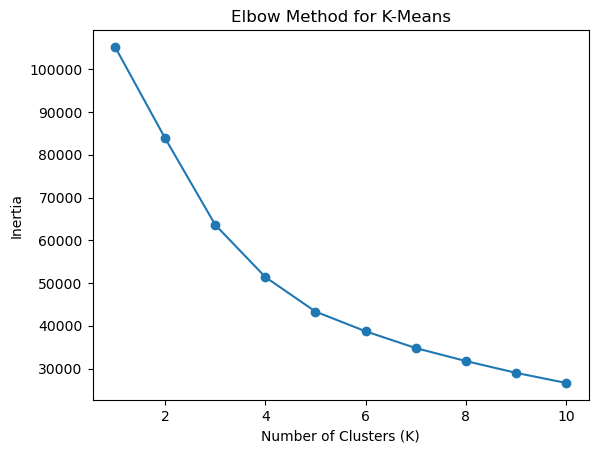

In [4]:
from sklearn.cluster import KMeans

inertias = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.show()

## K-Means - Silhouette Score Evaluation

In [5]:
from sklearn.metrics import silhouette_score

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled, labels,
        sample_size=3000,
        random_state=42
    )

    print(f"K={k}: Silhouette Score={score:.4f}")

K=2: Silhouette Score=0.0884
K=3: Silhouette Score=0.2970
K=4: Silhouette Score=0.3213
K=5: Silhouette Score=0.3435
K=6: Silhouette Score=0.3501
K=7: Silhouette Score=0.3680
K=8: Silhouette Score=0.4197


## K-Means - Comparing Candidate Cluster Counts

In [6]:
for k in [5, 8]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    print(f"\nK={k}")
    print(pd.Series(labels).value_counts().sort_index())


K=5
0    6385
1    5935
2     263
3    5606
4    8116
Name: count, dtype: int64

K=8
0    3906
1    3345
2    3263
3    4752
4     263
5    3742
6    3547
7    3487
Name: count, dtype: int64


## K-Means - Cluster Interpretation

In [7]:
for k in [5, 8]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    results = X_imputed.copy()
    results["cluster"] = labels

    print(f"\nK={k} — Average resource usage per cluster")
    display(results.groupby("cluster")[features].mean().round(2))


K=5 — Average resource usage per cluster


,cpu_utilization,memory_usage,storage_usage,workload
cluster,,,,
0,27.53,40.95,74.12,75.65
1,52.13,73.93,69.91,95.50
2,148.47,49.61,75.29,272.04
3,60.16,45.24,93.27,94.02
4,66.05,42.48,66.99,96.67



K=8 — Average resource usage per cluster


,cpu_utilization,memory_usage,storage_usage,workload
cluster,,,,
0,76.41,38.54,64.62,98.34
1,24.62,58.62,84.39,80.98
2,31.01,27.00,73.92,73.75
3,52.07,48.99,75.31,93.49
4,148.47,49.61,75.29,272.04
5,67.44,73.60,78.49,98.93
6,65.05,38.55,94.61,94.94
7,41.86,62.79,54.97,90.26


## K-Means - Investigating the Unusual Cluster

In [8]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

labels = kmeans.fit_predict(X_scaled)

results = X_imputed.copy()
results["cluster"] = labels

unusual = results[results["cluster"] == 2]

print("Unusual cluster size:", len(unusual))
display(unusual[features].describe().round(2))

Unusual cluster size: 263


,cpu_utilization,memory_usage,storage_usage,workload
count,263.00,263.00,263.00,263.00
mean,148.47,49.61,75.29,272.04
std,27.60,0.00,0.00,0.00
min,52.46,49.61,75.29,272.04
25%,156.37,49.61,75.29,272.04
50%,156.37,49.61,75.29,272.04
75%,156.37,49.61,75.29,272.04
max,156.37,49.61,75.29,272.04


## Investigating the Original Values of the Unusual Cluster

In [9]:
# Retrieve original rows corresponding to cluster 2
original_unusual = df.loc[unusual.index]

print("Missing values in original rows:")
print(original_unusual[features].isnull().sum())

print("\nMost frequent CPU values:")
print(original_unusual["cpu_utilization"].value_counts().head())

print("\nFirst five original observations:")
display(original_unusual.head())

Missing values in original rows:
cpu_utilization    20
memory_usage       30
storage_usage      33
workload            0
dtype: int64

Most frequent CPU values:
cpu_utilization
156.372919    243
Name: count, dtype: int64

First five original observations:


,timestamp,cpu_utilization,memory_usage,storage_usage,workload,Resource Allocation
196,2022-01-09 04:00:00,156.372919,49.610011,75.28984,272.035047,98.244543
345,2022-01-15 09:00:00,156.372919,49.610011,NaN,272.035047,NaN
474,2022-01-20 18:00:00,156.372919,49.610011,75.28984,272.035047,98.267383
536,2022-01-23 08:00:00,156.372919,49.610011,75.28984,272.035047,98.242597
640,2022-01-27 16:00:00,NaN,49.610011,75.28984,272.035047,98.247173


## K-Means - Cluster Visualization Using PCA

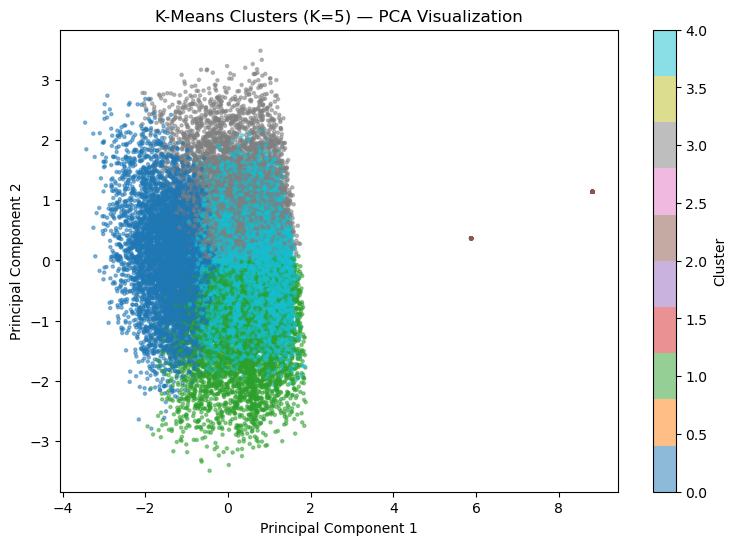

Variance explained: 0.696


In [10]:
from sklearn.decomposition import PCA

# Reduce 4 features to 2 dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot our existing K=5 clusters
plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="tab10",
    s=5,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (K=5) — PCA Visualization")
plt.colorbar(label="Cluster")
plt.show()

print("Variance explained:", pca.explained_variance_ratio_.sum().round(3))

### PCA - Understanding the Principal Components

In [11]:
loadings = pd.DataFrame(
    pca.components_,
    columns=features,
    index=["PC1", "PC2"]
)

display(loadings.round(3))

,cpu_utilization,memory_usage,storage_usage,workload
PC1,0.686,0.174,-0.051,0.705
PC2,0.181,-0.678,0.711,0.042


## DBSCAN - Finding an Appropriate Epsilon Value

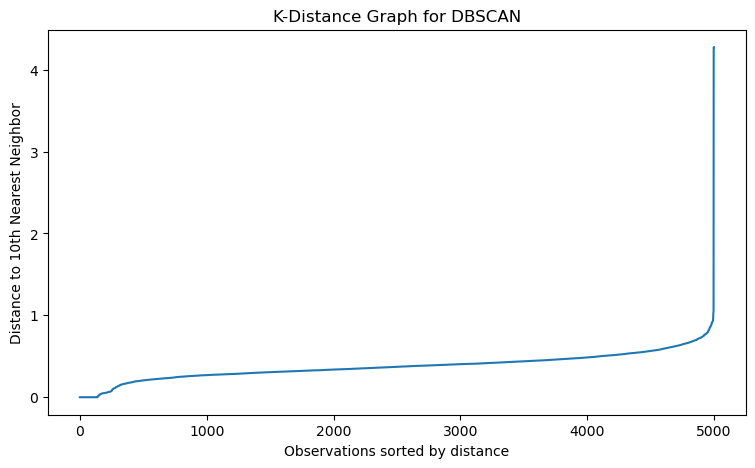

In [12]:
from sklearn.neighbors import NearestNeighbors

# Use a reproducible sample to keep DBSCAN efficient
rng = np.random.RandomState(123)
sample_indices = rng.choice(len(X_scaled), size=5000, replace=False)
X_sample = X_scaled[sample_indices]

# Calculate distances to the 10th nearest neighbor
neighbors = NearestNeighbors(n_neighbors=10)
neighbors.fit(X_sample)

distances, indices = neighbors.kneighbors(X_sample)
k_distances = np.sort(distances[:, 9])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel("Observations sorted by distance")
plt.ylabel("Distance to 10th Nearest Neighbor")
plt.title("K-Distance Graph for DBSCAN")
plt.show()

## DBSCAN - Initial Clustering

In [13]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.7, min_samples=10)

dbscan_labels = dbscan.fit_predict(X_sample)

print("Cluster sizes:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

Cluster sizes:
-1      15
 0    4926
 1      59
Name: count, dtype: int64


## DBSCAN - Parameter Tuning

In [14]:
for eps in [0.3, 0.4, 0.5, 0.6, 0.7]:
    model = DBSCAN(eps=eps, min_samples=10)
    labels_db = model.fit_predict(X_sample)

    n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
    n_noise = np.sum(labels_db == -1)

    print(f"eps={eps}: Clusters={n_clusters}, Noise={n_noise}")

eps=0.3: Clusters=13, Noise=2796
eps=0.4: Clusters=12, Noise=1112
eps=0.5: Clusters=3, Noise=335
eps=0.6: Clusters=2, Noise=63
eps=0.7: Clusters=2, Noise=15


### DBSCAN - Comparing Candidate Parameters

In [15]:
for eps in [0.5, 0.6]:
    model = DBSCAN(eps=eps, min_samples=10)
    labels_db = model.fit_predict(X_sample)

    print(f"\neps = {eps}")
    print(pd.Series(labels_db).value_counts().sort_index())


eps = 0.5
-1     335
 0    4592
 1      14
 2      59
Name: count, dtype: int64

eps = 0.6
-1      63
 0    4878
 1      59
Name: count, dtype: int64


## DBSCAN - Full Dataset Analysis

Initial DBSCAN experiments used a sample of 5,000 observations for computational efficiency. Since the results were dominated by one large cluster, we will investigate the full dataset to evaluate how data density affects clustering.

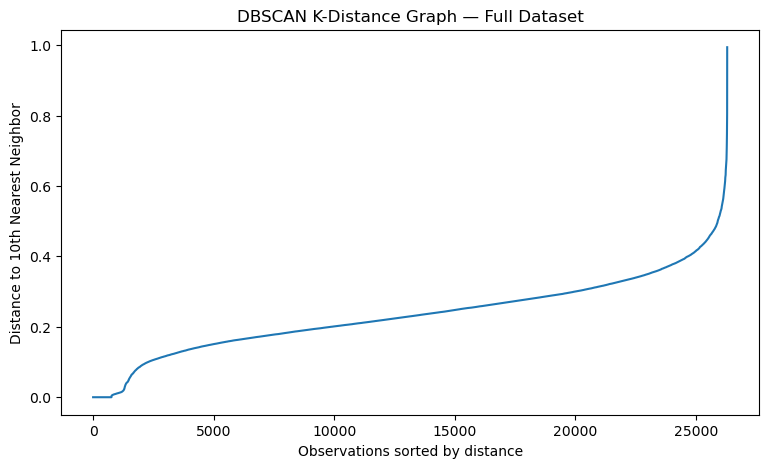

In [16]:
from sklearn.neighbors import NearestNeighbors

# Find the 10 nearest neighbors using all observations
neighbors_full = NearestNeighbors(n_neighbors=10)
neighbors_full.fit(X_scaled)

distances_full, _ = neighbors_full.kneighbors(X_scaled)

# Sort distances to the 10th nearest neighbor
k_distances_full = np.sort(distances_full[:, 9])

plt.figure(figsize=(9, 5))
plt.plot(k_distances_full)

plt.xlabel("Observations sorted by distance")
plt.ylabel("Distance to 10th Nearest Neighbor")
plt.title("DBSCAN K-Distance Graph — Full Dataset")
plt.show()

### DBSCAN - Full Dataset Parameter Comparison

In [17]:
from sklearn.cluster import DBSCAN

for eps in [0.4, 0.5]:
    model = DBSCAN(
        eps=eps,
        min_samples=10
    )

    labels_db = model.fit_predict(X_scaled)

    n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
    n_noise = np.sum(labels_db == -1)

    print(f"\neps = {eps}")
    print(f"Clusters: {n_clusters}")
    print(f"Noise points: {n_noise}")
    print(pd.Series(labels_db).value_counts().sort_index())


eps = 0.4
Clusters: 3
Noise points: 360
-1      360
 0    25682
 1      243
 2       20
Name: count, dtype: int64

eps = 0.5
Clusters: 3
Noise points: 47
-1       47
 0    25995
 1      243
 2       20
Name: count, dtype: int64


## DBSCAN - Interpretation of Small Clusters

In [18]:
dbscan = DBSCAN(eps=0.4, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)

dbscan_results = X_imputed.copy()
dbscan_results["cluster"] = dbscan_labels

print("Average resource usage by DBSCAN cluster:")
display(
    dbscan_results.groupby("cluster")[features]
    .mean()
    .round(2)
)

Average resource usage by DBSCAN cluster:


,cpu_utilization,memory_usage,storage_usage,workload
cluster,,,,
-1,30.69,44.33,74.46,70.12
0,52.47,49.95,75.07,90.97
1,156.37,49.61,75.29,272.04
2,52.46,49.61,75.29,272.04


## Sensitivity Analysis - Clustering Without the Unusual High-Load Group

K-Means identified a distinct group of 263 observations characterized by exceptionally high workload values. To investigate their influence on clustering, we temporarily exclude these observations and repeat the analysis. The original dataset remains unchanged.

In [19]:
# Identify the 263 unusual observations from our original K-Means model
unusual_indices = unusual.index

# Create a separate dataset excluding these observations
X_filtered = X_imputed.drop(index=unusual_indices).copy()

print("Original observations:", len(X_imputed))
print("Removed observations:", len(unusual_indices))
print("Remaining observations:", len(X_filtered))

Original observations: 26305
Removed observations: 263
Remaining observations: 26042


### Feature Scaling After Filtering

In [20]:
from sklearn.preprocessing import StandardScaler

scaler_filtered = StandardScaler()
X_filtered_scaled = scaler_filtered.fit_transform(X_filtered)

print("Filtered data shape:", X_filtered_scaled.shape)
print("Feature means:", X_filtered_scaled.mean(axis=0).round(2))
print("Standard deviations:", X_filtered_scaled.std(axis=0).round(2))

Filtered data shape: (26042, 4)
Feature means: [-0. -0.  0.  0.]
Standard deviations: [1. 1. 1. 1.]


### Elbow Method - Filtered Dataset

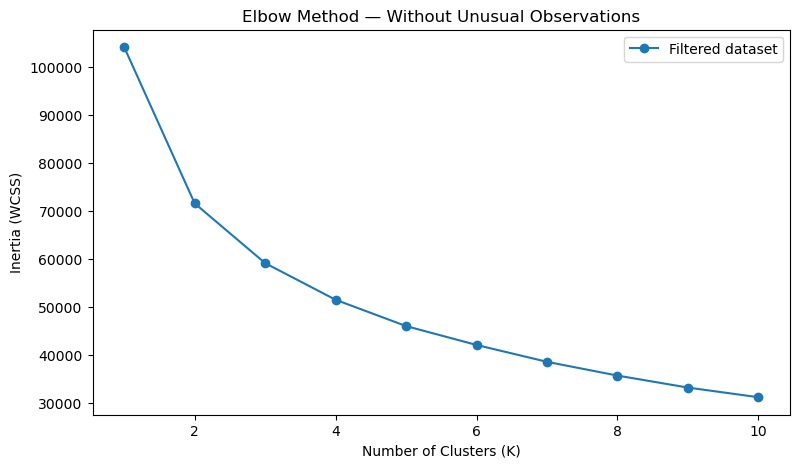

In [21]:
inertias_filtered = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_filtered_scaled)
    inertias_filtered.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(range(1, 11), inertias_filtered, marker='o',
         label='Filtered dataset')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method — Without Unusual Observations")
plt.legend()
plt.show()

### Silhouette Score - Filtered Dataset

In [22]:
from sklearn.metrics import silhouette_score

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_filtered = model.fit_predict(X_filtered_scaled)

    score = silhouette_score(
        X_filtered_scaled,
        labels_filtered,
        sample_size=3000,
        random_state=42
    )

    print(f"K={k}: Silhouette Score={score:.4f}")

K=2: Silhouette Score=0.2996
K=3: Silhouette Score=0.2328
K=4: Silhouette Score=0.2297
K=5: Silhouette Score=0.2190
K=6: Silhouette Score=0.2143
K=7: Silhouette Score=0.2151
K=8: Silhouette Score=0.2071


### Cluster Interpretation - Filtered Dataset (K=2)

In [23]:
kmeans_filtered = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

filtered_labels = kmeans_filtered.fit_predict(X_filtered_scaled)

filtered_results = X_filtered.copy()
filtered_results["cluster"] = filtered_labels

print("Cluster sizes:")
print(filtered_results["cluster"].value_counts().sort_index())

print("\nAverage resource usage by cluster:")
display(
    filtered_results.groupby("cluster")[features]
    .mean()
    .round(2)
)

Cluster sizes:
cluster
0     9381
1    16661
Name: count, dtype: int64

Average resource usage by cluster:


,cpu_utilization,memory_usage,storage_usage,workload
cluster,,,,
0,31.47,43.79,76.00,77.68
1,63.82,53.29,74.53,98.00


### PCA Visualization - Filtered Dataset

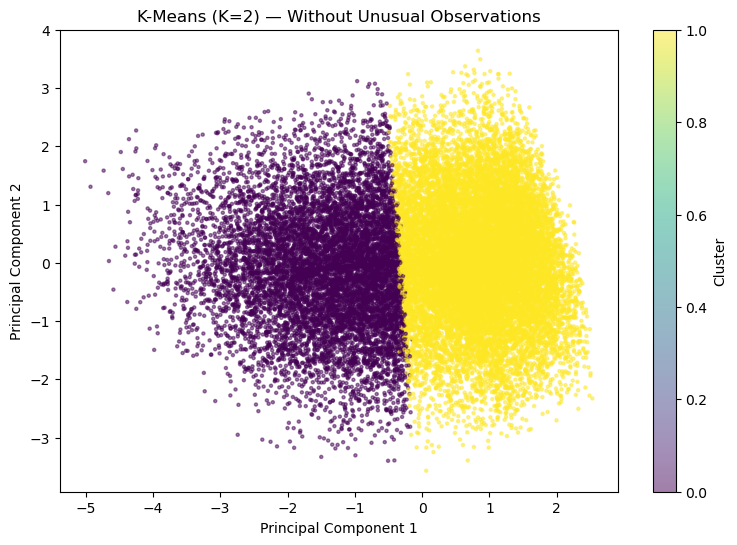

Variance explained: 0.708


In [24]:
pca_filtered = PCA(n_components=2)
X_filtered_pca = pca_filtered.fit_transform(X_filtered_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_filtered_pca[:, 0],
    X_filtered_pca[:, 1],
    c=filtered_labels,
    cmap="viridis",
    s=5,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means (K=2) — Without Unusual Observations")
plt.colorbar(label="Cluster")
plt.show()

print("Variance explained:",
      pca_filtered.explained_variance_ratio_.sum().round(3))

### DBSCAN - Filtered Dataset

In [25]:
# Apply DBSCAN to the filtered dataset
dbscan_filtered = DBSCAN(eps=0.4, min_samples=10)

filtered_dbscan_labels = dbscan_filtered.fit_predict(X_filtered_scaled)

# Count clusters and noise
n_clusters = len(set(filtered_dbscan_labels)) - (1 if -1 in filtered_dbscan_labels else 0)
n_noise = np.sum(filtered_dbscan_labels == -1)

print("Number of clusters:", n_clusters)
print("Noise observations:", n_noise)

print("\nCluster sizes:")
print(pd.Series(filtered_dbscan_labels).value_counts().sort_index())

Number of clusters: 7
Noise observations: 1488

Cluster sizes:
-1     1488
 0    24489
 1       12
 2        7
 3       19
 4        6
 5       13
 6        8
Name: count, dtype: int64


## K-Means Results and Interpretation

K-Means produced interpretable resource-usage clusters, while DBSCAN primarily identified one large dense group and smaller unusual groups. A sensitivity analysis excluding 263 high-load observations revealed two broader resource-usage patterns, demonstrating the influence of unusual observations on clustering.